In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import sys
sys.path.insert(0, '/content/drive/MyDrive/Stage')
import pandas as pd
import numpy as np

In [3]:

df = pd.read_csv("/content/drive/MyDrive/Stage/table-adresses-reu.csv", low_memory=False)


In [4]:
# Dimensions
print("Shape:", df.shape)

# Aperçu
df.head()


Shape: (15970992, 12)


,code_commune_ref,reconstitution_code_commune,id_brut_bv_reu,id,geo_adresse,geo_type,geo_score,longitude,latitude,api_line,nb_bv_commune,nb_adresses
0,01001,2,01001_1,01001_0045,Rue des Bles d'Or 01400 L'Abergement-Clémenciat,street,0.85,4.926090,46.151757,BANN,1,5
1,01001,1,01001_1,01001_0040_00101,101 Impasse Bellevue 01400 L'Abergement-Clémen...,housenumber,0.91,4.924261,46.134889,BANG,1,1
2,01001,1,01001_1,01001_0175_00106,106 Route des Garaudes 01400 L'Abergement-Clém...,housenumber,0.91,4.923428,46.133930,BANG,1,1
3,01001,1,01001_1,01001_0230_00190,190 Impasse des Lilas 01400 L'Abergement-Cléme...,housenumber,0.91,4.923083,46.146773,BANG,1,2
4,01001,2,01001_1,01001_0175_00192,192 Route des Garaudes 01400 L'Abergement-Clém...,housenumber,0.95,4.923743,46.133608,BANG,1,3


In [5]:
df.dtypes

,0
code_commune_ref,object
reconstitution_code_commune,int64
id_brut_bv_reu,object
id,object
geo_adresse,object
geo_type,object
geo_score,float64
longitude,float64
latitude,float64
api_line,object


In [6]:
# Valeurs manquantes
df.isna().sum()


,0
code_commune_ref,0
reconstitution_code_commune,0
id_brut_bv_reu,0
id,0
geo_adresse,0
geo_type,0
geo_score,0
longitude,0
latitude,0
api_line,0


In [7]:
# Nombre de bureaux uniques
df["id_brut_bv_reu"].nunique()


68830

In [8]:
# Nombre de communes
df["code_commune_ref"].nunique()


34991

In [9]:
# Distribution du score
df["geo_score"].describe()

,geo_score
count,1.597099e+07
mean,9.263459e-01
std,7.903426e-02
min,3.000000e-01
25%,9.400000e-01
50%,9.500000e-01
75%,9.600000e-01
max,9.900000e-01


In [10]:
df.groupby("id_brut_bv_reu")["id"].count().describe()

,id
count,68830.000000
mean,232.035333
std,160.070235
min,1.000000
25%,89.000000
50%,215.000000
75%,354.000000
max,1246.000000


In [11]:
df.duplicated().sum()

np.int64(0)

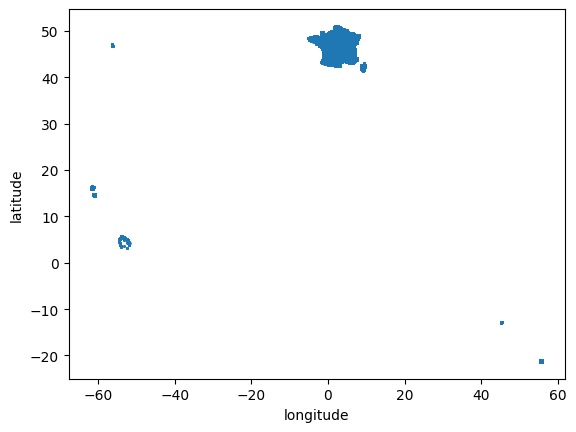

In [12]:
import matplotlib.pyplot as plt

df.plot.scatter(x="longitude", y="latitude", s=1)
plt.show()

In [14]:
# Combien d'adresses ont un score < 0.7 (géolocalisation médiocre) ?
print((df["geo_score"] < 0.7).sum())
print((df["geo_score"] < 0.7).mean() * 100, "% des adresses")

# Distribution par geo_type pour les scores faibles
df[df["geo_score"] < 0.7]["geo_type"].value_counts()

498577
3.121766011779356 % des adresses


,count
geo_type,
housenumber,340673
street,132206
locality,18422
municipality,7253
interpolation,20
village,3


In [15]:
df["geo_type"].value_counts(normalize=True).mul(100).round(1)

,proportion
geo_type,
housenumber,95.6
street,4.0
locality,0.4
municipality,0.1
interpolation,0.0
village,0.0


In [16]:
bv_counts = df.groupby("id_brut_bv_reu")["id"].count()
print("Bureaux avec moins de 5 adresses :", (bv_counts < 5).sum())

Bureaux avec moins de 5 adresses : 642


<Axes: xlabel='longitude', ylabel='latitude'>

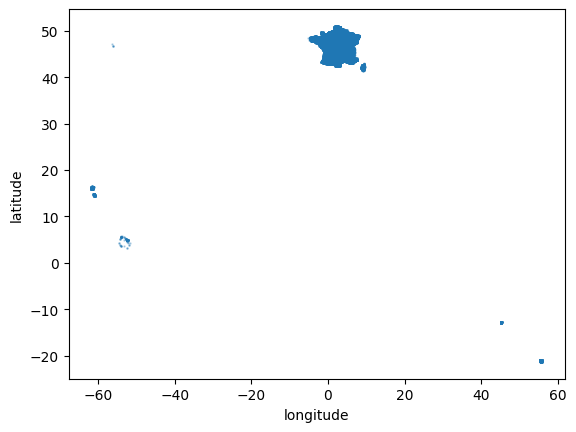

In [17]:
# Carte par densité : un point par bureau (centroïde moyen)
bv_centroids = df.groupby("id_brut_bv_reu")[["longitude","latitude"]].mean()
bv_centroids.plot.scatter(x="longitude", y="latitude", s=0.5, alpha=0.3)